In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv(r"C:\Users\Srihari\Downloads\winequality-red.csv")
print("jajajjajajaj")

jajajjajajaj


In [6]:
print("first 5 rows")
print(df.head())
print("dATASET SHAPE")
print(df.shape)ss


first 5 rows
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      

In [8]:
print("coloumn names")
print(df.columns)
print("missing values")
print(df.isnull().sum())
x=df.drop("quality",axis=1)
y=df["quality"]
normalizer=MinMaxScaler()
X_normalized=normalizer.fit_transform(x)
print("normalized data(5 rows)")
print(pd.DataFrame(X_normalized,columns=x.columns).head().round(3))


coloumn names
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')
missing values
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64
normalized data(5 rows)
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0          0.248             0.397         0.00           0.068      0.107   
1          0.283             0.521         0.00           0.116      0.144   
2          0.283             0.438         0.04           0.096      0.134   
3          0.584             0.110         0.56           0.068      0.105   
4        

In [10]:
standardizer=StandardScaler()
x_standardized = standardizer.fit_transform(x)
print("\n standardized data(5 rows)")
print(pd.DataFrame(x_standardized,columns = x.columns).head().round(3))


 standardized data(5 rows)
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0         -0.528             0.962       -1.391          -0.453     -0.244   
1         -0.299             1.967       -1.391           0.043      0.224   
2         -0.299             1.297       -1.186          -0.169      0.096   
3          1.655            -1.384        1.484          -0.453     -0.265   
4         -0.528             0.962       -1.391          -0.453     -0.244   

   free sulfur dioxide  total sulfur dioxide  density     pH  sulphates  \
0               -0.466                -0.379    0.558  1.289     -0.579   
1                0.873                 0.624    0.028 -0.720      0.129   
2               -0.084                 0.229    0.134 -0.331     -0.048   
3                0.108                 0.412    0.664 -0.979     -0.461   
4               -0.466                -0.379    0.558  1.289     -0.579   

   alcohol  
0   -0.960  
1   -0.585  
2   -0.585  


In [12]:
pca = PCA(n_components=2)
x_pca=pca.fit_transform(x_standardized)
print("pca output (5rows)")
print(pd.DataFrame(x_pca,columns=["PC1","PC2"]).head().round(3))

pca output (5rows)
     PC1    PC2
0 -1.620  0.451
1 -0.799  1.857
2 -0.748  0.882
3  2.358 -0.270
4 -1.620  0.451


In [15]:
print("original no of features",x.shape[1])
print("reduced shape ",x_pca.shape[1])
print("varaince reatined by each component")
print(pca.explained_variance_ratio_.round(4))
print("total varince retained ",round(sum(pca.explained_variance_ratio_)*100,2),"%")

original no of features 11
reduced shape  2
varaince reatined by each component
[0.2817 0.1751]
total varince retained  45.68 %


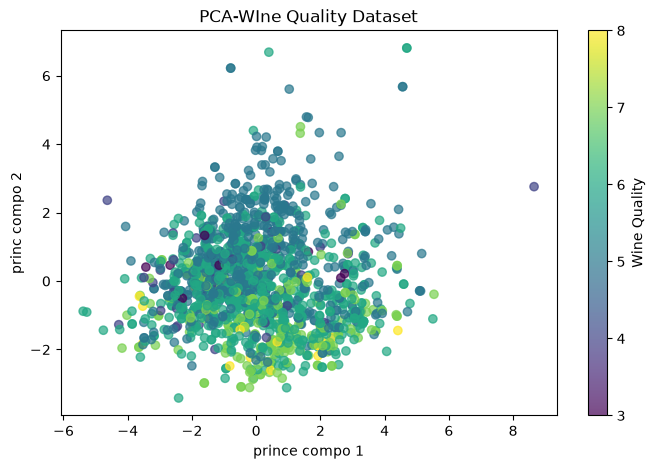

In [17]:
plt.figure(figsize =(8,5))
plt.scatter(x_pca[:,0],x_pca[:,1],c=y,cmap = "viridis",alpha=0.7)
plt.xlabel("prince compo 1")
plt.ylabel("princ compo 2")
plt.title("PCA-WIne Quality Dataset")
plt.colorbar(label ="Wine Quality")
plt.show()